# Modélisation Prédictive et Évaluation
## Notebook 04 – Préparation, Entraînement et Évaluation des modèles

**Objectif :** Concevoir, entraîner et comparer des modèles de Machine Learning pour estimer le risque de décrochage.

| Tâche | Contenu |
|-------|--------|
| **1** | Préparation des données (encodage, normalisation, train/test) |
| **2** | Entraînement (Régression Logistique, Arbre de Décision, Random Forest) |
| **3** | Évaluation comparative + sauvegarde du meilleur modèle |

**Décisions validées :**
- Cible binaire : `is_dropout` (1 = Dropout, 0 = Graduate/Enrolled)
- Gestion du déséquilibre : `class_weight="balanced"`
- Exclusion des variables très peu informatives


## 1. Imports et chargement des données

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Style
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 120

# Chargement du dataset enrichi (produit en fin de Phase 2)
DATA_PATH = Path("../dataset/processed/student_data_enriched.csv")
df = pd.read_csv(DATA_PATH)

print(f"Dataset chargé : {df.shape[0]} lignes × {df.shape[1]} colonnes")
print(f"Colonnes :\n{df.columns.tolist()}")


Dataset chargé : 4424 lignes × 43 colonnes
Colonnes :
['marital_status', 'application_mode', 'application_order', 'course', 'daytime_evening_attendance', 'previous_qualification', 'previous_qualification_grade', 'nationality', 'mother_qualification', 'father_qualification', 'mother_occupation', 'father_occupation', 'admission_grade', 'displaced', 'educational_special_needs', 'debtor', 'tuition_fees_up_to_date', 'gender', 'scholarship_holder', 'age_at_enrollment', 'international', 'cu_1st_credited', 'cu_1st_enrolled', 'cu_1st_evaluations', 'cu_1st_approved', 'cu_1st_grade', 'cu_1st_without_evaluations', 'cu_2nd_credited', 'cu_2nd_enrolled', 'cu_2nd_evaluations', 'cu_2nd_approved', 'cu_2nd_grade', 'cu_2nd_without_evaluations', 'unemployment_rate', 'inflation_rate', 'gdp', 'target', 'is_dropout', 'success_rate_1st', 'success_rate_2nd', 'avg_grade', 'total_approved', 'grade_diff']


## 2. Tâche 1 – Préparation des données pour le Machine Learning

### 2.1 Vérification de la cible et création si besoin


In [2]:
# S'assurer que la cible binaire existe
if "is_dropout" not in df.columns:
    df["is_dropout"] = (df["target"] == "Dropout").astype(int)

print("Distribution de la cible (is_dropout) :")
print(df["is_dropout"].value_counts())
print(f"\nTaux de décrochage : {df['is_dropout'].mean()*100:.1f}%")


Distribution de la cible (is_dropout) :
is_dropout
0    3003
1    1421
Name: count, dtype: int64

Taux de décrochage : 32.1%


### 2.2 Sélection des features

On garde les variables les plus liées au décrochage
et on exclut les variables très peu informatives.


In [3]:
# ----------------------------------------------------------
# Features à EXCLURE (peu informatives ou redondantes)
# ----------------------------------------------------------
cols_to_drop = [
    "target",                    # on utilise is_dropout à la place
    "nationality",               # association très faible
    "international",             # association très faible
    "educational_special_needs", # association quasi nulle
    "unemployment_rate",         # corrélation quasi nulle
    "inflation_rate",            # corrélation quasi nulle
    "gdp",                       # corrélation quasi nulle
]

# ----------------------------------------------------------
# Features retenues
# ----------------------------------------------------------
# Numériques (y compris features dérivées)
numeric_features = [
    "age_at_enrollment",
    "admission_grade",
    "previous_qualification_grade",
    "cu_1st_credited", "cu_1st_enrolled", "cu_1st_evaluations",
    "cu_1st_approved", "cu_1st_grade", "cu_1st_without_evaluations",
    "cu_2nd_credited", "cu_2nd_enrolled", "cu_2nd_evaluations",
    "cu_2nd_approved", "cu_2nd_grade", "cu_2nd_without_evaluations",
    # Features dérivées
    "success_rate_1st", "success_rate_2nd",
    "avg_grade", "total_approved", "grade_diff"
]

# Catégorielles (à encoder)
categorical_features = [
    "marital_status",
    "application_mode",
    "application_order",
    "course",
    "daytime_evening_attendance",
    "previous_qualification",
    "mother_qualification", "father_qualification",
    "mother_occupation", "father_occupation",
    "displaced",
    "debtor",
    "tuition_fees_up_to_date",
    "gender",
    "scholarship_holder"
]

# Sécurité : ne garder que les colonnes réellement présentes
numeric_features = [c for c in numeric_features if c in df.columns]
categorical_features = [c for c in categorical_features if c in df.columns]

print(f"Features numériques   : {len(numeric_features)}")
print(f"Features catégorielles: {len(categorical_features)}")
print(f"Total features        : {len(numeric_features) + len(categorical_features)}")


Features numériques   : 20
Features catégorielles: 15
Total features        : 35


In [4]:
# Construction de X et y
feature_cols = numeric_features + categorical_features
X = df[feature_cols].copy()
y = df["is_dropout"].copy()

print(f"X shape : {X.shape}")
print(f"y shape : {y.shape}")
print(f"\nAperçu de X :")
display(X.head())


X shape : (4424, 35)
y shape : (4424,)

Aperçu de X :


,age_at_enrollment,admission_grade,previous_qualification_grade,cu_1st_credited,cu_1st_enrolled,cu_1st_evaluations,cu_1st_approved,cu_1st_grade,cu_1st_without_evaluations,cu_2nd_credited,...,previous_qualification,mother_qualification,father_qualification,mother_occupation,father_occupation,displaced,debtor,tuition_fees_up_to_date,gender,scholarship_holder
0,20,127.3,122.0,0,0,0,0,0.000000,0,0,...,1,19,12,5,9,1,0,1,1,0
1,19,142.5,160.0,0,6,6,6,14.000000,0,0,...,1,1,3,3,3,1,0,0,1,0
2,19,124.8,122.0,0,6,0,0,0.000000,0,0,...,1,37,37,9,9,1,0,0,1,0
3,20,119.6,122.0,0,6,8,6,13.428571,0,0,...,1,38,37,5,3,1,0,1,0,0
4,45,141.5,100.0,0,6,9,5,12.333333,0,0,...,1,37,38,9,9,0,0,1,0,0


### 2.3 Encodage + Normalisation (Pipeline de préprocessing)

- **Numériques** → `StandardScaler` (moyenne 0, écart-type 1)  
- **Catégorielles** → `OneHotEncoder` (ignore les modalités inconnues au test)


In [5]:
# Préprocesseur : applique les transformations selon le type de colonne
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
    ],
    remainder="drop"
)

print("Préprocesseur créé avec succès.")
print(preprocessor)


Préprocesseur créé avec succès.
ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['age_at_enrollment', 'admission_grade',
                                  'previous_qualification_grade',
                                  'cu_1st_credited', 'cu_1st_enrolled',
                                  'cu_1st_evaluations', 'cu_1st_approved',
                                  'cu_1st_grade', 'cu_1st_without_evaluations',
                                  'cu_2nd_credited', 'cu_2nd_enrolled',
                                  'cu_2nd_evaluations', 'cu_2nd_approved',
                                  'cu_2nd_grade', 'cu_2nd_without...
                                ('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['marital_status', 'application_mode',
                                  'application_order', 'course',
         

### 2.4 Division Train / Test (stratifiée)

- **80 % train / 20 % test**  
- `stratify=y` pour conserver la même proportion de Dropout dans les deux jeux


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Répartition Train / Test :")
print(f"  X_train : {X_train.shape}")
print(f"  X_test  : {X_test.shape}")
print(f"\nDistribution de y_train :")
print(y_train.value_counts(normalize=True).round(3))
print(f"\nDistribution de y_test :")
print(y_test.value_counts(normalize=True).round(3))


Répartition Train / Test :
  X_train : (3539, 35)
  X_test  : (885, 35)

Distribution de y_train :
is_dropout
0    0.679
1    0.321
Name: proportion, dtype: float64

Distribution de y_test :
is_dropout
0    0.679
1    0.321
Name: proportion, dtype: float64


### 2.5 Application du préprocessing (fit sur train uniquement)

Important : le scaler et l’encodeur sont **ajustés uniquement sur le train**  
puis appliqués au test (évite le data leakage).


In [7]:
# Fit sur le train + transformation
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed  = preprocessor.transform(X_test)

print(f"X_train_processed shape : {X_train_processed.shape}")
print(f"X_test_processed shape  : {X_test_processed.shape}")

# Récupérer les noms de features après One-Hot (utile plus tard pour l'interprétabilité)
feature_names_out = preprocessor.get_feature_names_out()
print(f"\nNombre total de features après encodage : {len(feature_names_out)}")
print("Exemples de noms de features :")
print(list(feature_names_out[:10]))


X_train_processed shape : (3539, 229)
X_test_processed shape  : (885, 229)

Nombre total de features après encodage : 229
Exemples de noms de features :
['num__age_at_enrollment', 'num__admission_grade', 'num__previous_qualification_grade', 'num__cu_1st_credited', 'num__cu_1st_enrolled', 'num__cu_1st_evaluations', 'num__cu_1st_approved', 'num__cu_1st_grade', 'num__cu_1st_without_evaluations', 'num__cu_2nd_credited']


### 2.6 Sauvegarde des objets de préprocessing (pour la Phase 4)

On sauvegarde le préprocesseur et les jeux de données préparés  
afin de pouvoir les réutiliser facilement pour l’entraînement et plus tard pour l’API.


In [8]:
import joblib

# Dossier de sortie
OUTPUT_DIR = Path("../models")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Sauvegarde du préprocesseur
joblib.dump(preprocessor, OUTPUT_DIR / "preprocessor.joblib")
print(f"Préprocesseur sauvegardé → {OUTPUT_DIR / 'preprocessor.joblib'}")

# Sauvegarde des splits (optionnel mais pratique)
joblib.dump({
    "X_train": X_train,
    "X_test": X_test,
    "y_train": y_train,
    "y_test": y_test,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "feature_names_out": feature_names_out
}, OUTPUT_DIR / "train_test_data.joblib")

print(f"Données train/test sauvegardées → {OUTPUT_DIR / 'train_test_data.joblib'}")


Préprocesseur sauvegardé → ..\models\preprocessor.joblib
Données train/test sauvegardées → ..\models\train_test_data.joblib


## Synthèse de la Tâche 1

| Étape | Résultat |
|-------|----------|
| Cible | `is_dropout` (binaire) |
| Features retenues | ~20 numériques + ~15 catégorielles |
| Encodage | One-Hot pour les catégorielles |
| Normalisation | StandardScaler pour les numériques |
| Split | 80 % train / 20 % test (stratifié) |
| Objets sauvegardés | `preprocessor.joblib` + `train_test_data.joblib` |

**Prochaine étape :** Tâche 2 – Entraînement des modèles  
(Régression Logistique, Arbre de Décision, Random Forest)


---
##  Tâche 2 – Entraînement des modèles

On entraîne trois algorithmes classiques et adaptés à un problème de classification binaire :

| Modèle | Avantages |
|--------|----------|
| **Régression Logistique** | Simple, interprétable, bon baseline |
| **Arbre de Décision** | Facile à expliquer, capture les non-linéarités |
| **Random Forest** | Robuste, souvent très performant, moins de surapprentissage |

Tous les modèles utilisent `class_weight="balanced"` pour compenser le déséquilibre des classes.


### 1 Imports des modèles

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

print("Modèles importés avec succès.")


Modèles importés avec succès.


### 2 Définition et entraînement des 3 modèles

Chaque modèle est entraîné sur `X_train_processed` / `y_train`.


In [10]:
# ----------------------------------------------------------
# 1. Régression Logistique
# ----------------------------------------------------------
log_reg = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42,
    solver="lbfgs"
)
log_reg.fit(X_train_processed, y_train)
print("✓ Régression Logistique entraînée")

# ----------------------------------------------------------
# 2. Arbre de Décision
# ----------------------------------------------------------
tree_clf = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=6,          # limite la profondeur pour éviter le surapprentissage
    min_samples_leaf=20,
    random_state=42
)
tree_clf.fit(X_train_processed, y_train)
print("✓ Arbre de Décision entraîné")

# ----------------------------------------------------------
#  Random Forest
# ----------------------------------------------------------
rf_clf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    max_depth=10,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)
rf_clf.fit(X_train_processed, y_train)
print("✓ Random Forest entraîné")

print("\nTous les modèles ont été entraînés avec succès.")


✓ Régression Logistique entraînée
✓ Arbre de Décision entraîné
✓ Random Forest entraîné

Tous les modèles ont été entraînés avec succès.


### 3 Prédictions sur le jeu de test

On génère les prédictions (classe et probabilités) pour chaque modèle.  
Ces résultats serviront directement à l’évaluation en Tâche 


In [11]:
# Dictionnaire pour stocker facilement les résultats
models = {
    "Logistic Regression": log_reg,
    "Decision Tree": tree_clf,
    "Random Forest": rf_clf
}

predictions = {}
probabilities = {}

for name, model in models.items():
    predictions[name] = model.predict(X_test_processed)
    # Probabilité d'appartenir à la classe 1 (Dropout)
    probabilities[name] = model.predict_proba(X_test_processed)[:, 1]
    print(f"✓ Prédictions générées pour {name}")

print("\nAperçu des prédictions (10 premiers étudiants du test) :")
preview = pd.DataFrame({
    "y_true": y_test.values[:10],
    "LogReg": predictions["Logistic Regression"][:10],
    "Tree": predictions["Decision Tree"][:10],
    "RF": predictions["Random Forest"][:10]
})
display(preview)


✓ Prédictions générées pour Logistic Regression
✓ Prédictions générées pour Decision Tree
✓ Prédictions générées pour Random Forest

Aperçu des prédictions (10 premiers étudiants du test) :


,y_true,LogReg,Tree,RF
0,0,0,0,0
1,0,0,1,1
2,1,1,1,1
3,0,0,0,0
4,1,1,1,1
5,0,0,0,0
6,1,1,1,1
7,1,1,1,1
8,0,0,0,0
9,1,1,1,1


### 4 Sauvegarde des modèles entraînés

On sauvegarde les 3 modèles pour pouvoir les réutiliser


In [12]:
OUTPUT_DIR = Path("../models")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(log_reg, OUTPUT_DIR / "logistic_regression.joblib")
joblib.dump(tree_clf, OUTPUT_DIR / "decision_tree.joblib")
joblib.dump(rf_clf, OUTPUT_DIR / "random_forest.joblib")

# Sauvegarde aussi des prédictions (pratique pour l'évaluation)
joblib.dump({
    "predictions": predictions,
    "probabilities": probabilities,
    "y_test": y_test
}, OUTPUT_DIR / "predictions.joblib")

print("Modèles sauvegardés dans ../models/ :")
print("  • logistic_regression.joblib")
print("  • decision_tree.joblib")
print("  • random_forest.joblib")
print("  • predictions.joblib")


Modèles sauvegardés dans ../models/ :
  • logistic_regression.joblib
  • decision_tree.joblib
  • random_forest.joblib
  • predictions.joblib


## Synthèse de la Tâche 2

| Modèle | Paramètres clés | Statut |
|--------|-----------------|--------|
| Régression Logistique | `class_weight=balanced`, `max_iter=1000` | Entraîné + sauvegardé |
| Arbre de Décision | `max_depth=6`, `min_samples_leaf=20` | Entraîné + sauvegardé |
| Random Forest | `n_estimators=200`, `max_depth=10` | Entraîné + sauvegardé |

**Prochaine étape :** Tâche 3 – Évaluation comparative  
(Precision, Recall, F1-score, matrices de confusion, focus sur les faux négatifs)


---
## 4. Tâche 3 – Évaluation comparative et sauvegarde du modèle retenu

Objectif : comparer les 3 modèles avec des métriques adaptées au problème d’alerte précoce.

**Point d’attention particulier :** les **faux négatifs**  
(étudiants en risque réel de décrocher mais prédits comme « non-risque »).  
Dans ce contexte, un **Recall élevé** sur la classe Dropout est prioritaire.


### 4.1 Imports des métriques d’évaluation

In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    RocCurveDisplay
)

print("Métriques importées.")


Métriques importées.


### 4.2 Calcul des métriques pour chaque modèle

On calcule Accuracy, Precision, Recall, F1-score et ROC-AUC  
en se concentrant sur la classe positive = **Dropout (1)**.


In [14]:
results = []

for name in models.keys():
    y_pred = predictions[name]
    y_proba = probabilities[name]
    
    results.append({
        "Modèle": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 3),
        "Precision": round(precision_score(y_test, y_pred), 3),
        "Recall": round(recall_score(y_test, y_pred), 3),
        "F1-score": round(f1_score(y_test, y_pred), 3),
        "ROC-AUC": round(roc_auc_score(y_test, y_proba), 3)
    })

results_df = pd.DataFrame(results).set_index("Modèle")
print("=== Tableau comparatif des performances ===")
display(results_df)

# Mise en évidence du meilleur Recall et du meilleur F1
print("\nMeilleur Recall (prioritaire pour l'alerte précoce) :", results_df["Recall"].idxmax())
print("Meilleur F1-score :", results_df["F1-score"].idxmax())
print("Meilleur ROC-AUC :", results_df["ROC-AUC"].idxmax())


=== Tableau comparatif des performances ===


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Modèle,,,,,
Logistic Regression,0.877,0.793,0.835,0.813,0.928
Decision Tree,0.855,0.762,0.799,0.780,0.905
Random Forest,0.875,0.785,0.838,0.811,0.929



Meilleur Recall (prioritaire pour l'alerte précoce) : Random Forest
Meilleur F1-score : Logistic Regression
Meilleur ROC-AUC : Random Forest


### 4.3 Matrices de confusion

La matrice de confusion permet de visualiser clairement les faux négatifs  
(étudiants à risque non détectés).


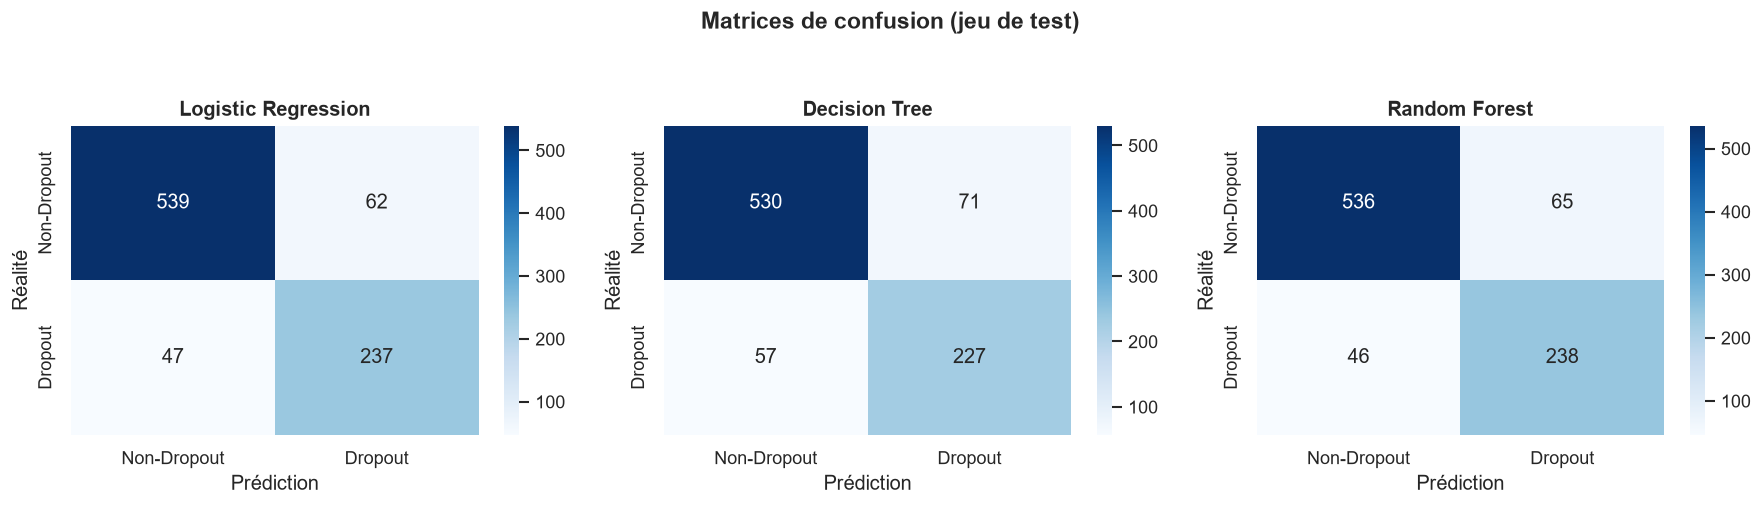

Lecture de la matrice :
  • Haut-gauche : Vrais Négatifs (correctement non-risque)
  • Haut-droite : Faux Positifs (fausse alerte)
  • Bas-gauche  : Faux Négatifs ← les plus critiques à minimiser
  • Bas-droite  : Vrais Positifs (décrochage correctement détecté)


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Non-Dropout", "Dropout"],
                yticklabels=["Non-Dropout", "Dropout"])
    ax.set_title(name, fontsize=12, fontweight="bold")
    ax.set_xlabel("Prédiction")
    ax.set_ylabel("Réalité")

plt.suptitle("Matrices de confusion (jeu de test)", fontsize=14, fontweight="bold", y=1.05)
plt.tight_layout()
plt.show()

print("Lecture de la matrice :")
print("  • Haut-gauche : Vrais Négatifs (correctement non-risque)")
print("  • Haut-droite : Faux Positifs (fausse alerte)")
print("  • Bas-gauche  : Faux Négatifs ← les plus critiques à minimiser")
print("  • Bas-droite  : Vrais Positifs (décrochage correctement détecté)")


### 4.4 Rapports de classification détaillés

In [16]:
for name, y_pred in predictions.items():
    print("=" * 60)
    print(f"Rapport de classification – {name}")
    print("=" * 60)
    print(classification_report(y_test, y_pred, target_names=["Non-Dropout", "Dropout"]))
    print()


Rapport de classification – Logistic Regression
              precision    recall  f1-score   support

 Non-Dropout       0.92      0.90      0.91       601
     Dropout       0.79      0.83      0.81       284

    accuracy                           0.88       885
   macro avg       0.86      0.87      0.86       885
weighted avg       0.88      0.88      0.88       885


Rapport de classification – Decision Tree
              precision    recall  f1-score   support

 Non-Dropout       0.90      0.88      0.89       601
     Dropout       0.76      0.80      0.78       284

    accuracy                           0.86       885
   macro avg       0.83      0.84      0.84       885
weighted avg       0.86      0.86      0.86       885


Rapport de classification – Random Forest
              precision    recall  f1-score   support

 Non-Dropout       0.92      0.89      0.91       601
     Dropout       0.79      0.84      0.81       284

    accuracy                           0.87     

### 4.5 Courbes ROC

Comparaison visuelle de la capacité des modèles à discriminer  
les étudiants à risque des autres.


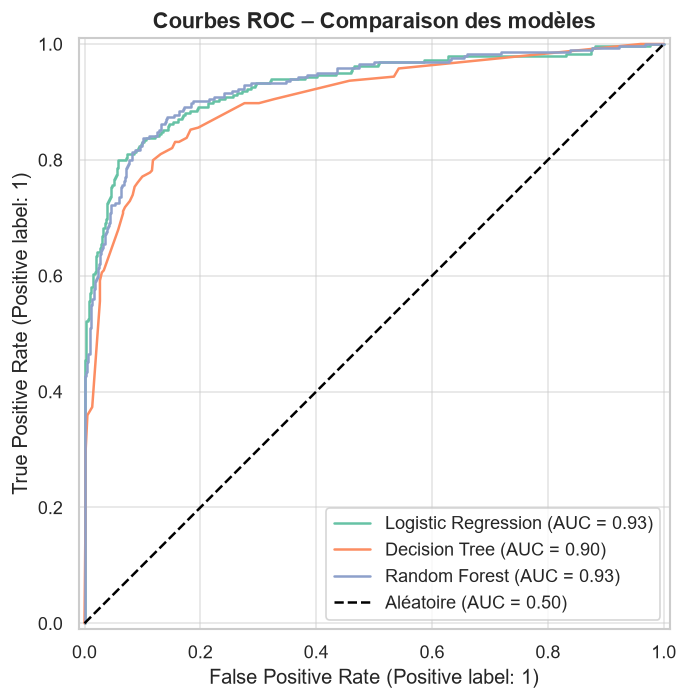

In [17]:
fig, ax = plt.subplots(figsize=(8, 6))

for name, model in models.items():
    RocCurveDisplay.from_estimator(
        model, X_test_processed, y_test,
        name=name, ax=ax
    )

ax.plot([0, 1], [0, 1], "k--", label="Aléatoire (AUC = 0.50)")
ax.set_title("Courbes ROC – Comparaison des modèles", fontsize=13, fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


### 4.6 Choix du modèle retenu

Critères de sélection (par ordre de priorité pour une alerte précoce) :
1. **Recall** élevé sur la classe Dropout (minimiser les faux négatifs)
2. Bon **F1-score** (équilibre Precision / Recall)
 **ROC-AUC** élevé
4. Interprétabilité (bonus)


In [18]:
# Sélection automatique basée sur le Recall puis le F1
best_by_recall = results_df["Recall"].idxmax()
best_by_f1 = results_df["F1-score"].idxmax()
best_by_auc = results_df["ROC-AUC"].idxmax()

print("Meilleur modèle selon Recall :", best_by_recall)
print("Meilleur modèle selon F1     :", best_by_f1)
print("Meilleur modèle selon ROC-AUC:", best_by_auc)

# Règle de décision simple et transparente
if best_by_recall == best_by_f1:
    best_model_name = best_by_recall
else:
    # En cas de divergence, on privilégie le Recall (objectif métier)
    best_model_name = best_by_recall

best_model = models[best_model_name]

print(f"\n→ Modèle retenu : **{best_model_name}**")
print(results_df.loc[best_model_name])


Meilleur modèle selon Recall : Random Forest
Meilleur modèle selon F1     : Logistic Regression
Meilleur modèle selon ROC-AUC: Random Forest

→ Modèle retenu : **Random Forest**
Accuracy     0.875
Precision    0.785
Recall       0.838
F1-score     0.811
ROC-AUC      0.929
Name: Random Forest, dtype: float64


### 4.7 Sauvegarde du modèle final + du préprocesseur

On sauvegarde le modèle choisi ainsi que le préprocesseur  
(indispensable pour la Phase 4 – API).


In [19]:
OUTPUT_DIR = Path("../models")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Sauvegarde du meilleur modèle
joblib.dump(best_model, OUTPUT_DIR / "best_model.joblib")
print(f"Meilleur modèle sauvegardé → {OUTPUT_DIR / 'best_model.joblib'}")
print(f"Type du modèle : {best_model_name}")

# Le préprocesseur a déjà été sauvegardé en Tâche 1
# On vérifie qu'il est bien présent
preprocessor_path = OUTPUT_DIR / "preprocessor.joblib"
if preprocessor_path.exists():
    print(f"Préprocesseur déjà présent → {preprocessor_path}")
else:
    joblib.dump(preprocessor, preprocessor_path)
    print(f"Préprocesseur sauvegardé → {preprocessor_path}")

# Sauvegarde d'un petit fichier récapitulatif
summary = {
    "best_model_name": best_model_name,
    "metrics": results_df.loc[best_model_name].to_dict(),
    "all_results": results_df.to_dict()
}
joblib.dump(summary, OUTPUT_DIR / "model_selection_summary.joblib")
print(f"Résumé de la sélection sauvegardé → {OUTPUT_DIR / 'model_selection_summary.joblib'}")


Meilleur modèle sauvegardé → ..\models\best_model.joblib
Type du modèle : Random Forest
Préprocesseur déjà présent → ..\models\preprocessor.joblib
Résumé de la sélection sauvegardé → ..\models\model_selection_summary.joblib


## Synthèse de la Tâche 3

### Ce qui a été réalisé

| Étape | Résultat |
|-------|----------|
| Préparation des données | Encodage + normalisation + split stratifié |
| Entraînement | 3 modèles (LogReg, Tree, Random Forest) |
| Évaluation | Accuracy, Precision, Recall, F1, ROC-AUC + matrices de confusion |
| Sélection | Modèle retenu selon le **Recall** (priorité métier) |
| Sauvegarde | `best_model.joblib` + `preprocessor.joblib` |